# Cuba water geographic names

Explore the names of Cuba’s streams, canals, ditches, lakes, lagoons, reservoirs,
bays and other water features. Each consolidated name object has one ID, preferred
name, string-array alternatives, detailed feature type, preferred-name source
reference and one Point location.

Run the cells in order from `examples/`, using **GeoPandas**, **Pandas** and **PyArrow**.
The previews show five records rather than listing the complete registry.


## Load the data

Read [Water Geographic Names](../data/water-geographic-names/) as GeoParquet.
Each geometry is one **Point in EPSG:4326**, WGS 84 longitude and latitude.
A name’s Point locates the object; it does not describe the extent of a river or
water-body polygon. Names remain in the list even when no physical feature has
an assigned name ID.


In [1]:
from pathlib import Path
import json
import geopandas as gpd

ROOT = Path("..")
names = gpd.read_parquet(ROOT / "data/water-geographic-names/cuba_water_geographic_names.parquet")
print(f"Rows: {len(names):,}")
print(f"Columns: {len(names.columns)}")


Rows: 8,984
Columns: 6


## Fields

- `id`: consolidated name object identifier.
- `preferred_name`: selected, type-complete label.
- `alternative_names`: a JSON array of strings belonging to this object.
- `object_type`: detailed feature type, such as stream, canal, lagoon or reservoir.
- `source_observations`: source references for the preferred name only; `other` means no documented source, with no invented source ID.
- `geometry`: one Point from the preferred-name source. Recorded coordinates are used where available; otherwise a representative point comes from the original source geometry. Selection details remain in the workflow audit.

See [fields.json](../data/water-geographic-names/fields.json) for definitions.


In [2]:
structure = names.dtypes.astype(str).rename_axis("Column").reset_index(name="Data type")
print(structure.to_string(index=False))


             Column Data type
                 id       str
     preferred_name       str
  alternative_names       str
        object_type       str
source_observations       str
           geometry  geometry


## Preview the names

Alternative names contain strings, without source records or object references.
Decode them with `json.loads(...)`.


In [3]:
preview = names[["preferred_name", "object_type", "alternative_names"]].head().copy()
preview["alternative_names"] = preview["alternative_names"].map(lambda values: "; ".join(json.loads(values)))
preview = preview.rename(columns={"preferred_name": "Geographic name", "object_type": "Feature type", "alternative_names": "Alternative names"})
print(preview.to_string(index=False))


          Geographic name Feature type Alternative names
         Embalse Jucarral    reservoir                  
         Embalse La Ceiba    reservoir                  
Laguna de Mala Habitación       lagoon                  
           Embalse Caonao    reservoir      Presa Caonao
        Embalse Voladoras    reservoir                  


## Count feature types

The detailed types distinguish rivers and canals from lakes, reservoirs, bays
and other features.


In [4]:
counts = names["object_type"].fillna("Unresolved type").value_counts().rename_axis("Feature type").reset_index(name="Name objects")
print(counts.to_string(index=False))


              Feature type  Name objects
                    stream          4805
                      cove           421
                       bay           361
                    lagoon           352
                 reservoir           348
                     canal           339
            marine channel           292
                      cape           211
                     water           198
                      pond           186
                     drain           171
                     ditch           151
                     shoal           148
                      lake           111
               tidal creek           104
             swimming pool            88
                      reef            71
                   estuary            70
                   channel            67
                     inlet            63
              stream mouth            59
                     marsh            56
                 waterfall            36
                

## List names of selected feature types

The example below displays the selected feature types as numbered lists, with
alternative names in parentheses. Each type appears as a heading.

In `selected_types`, uncomment the types you want to include and comment out
those you want to exclude. You can select one or several types. After editing,
rerun the list and map cells to update both outputs.


In [5]:
selected_types = [
    # "abandoned watercourse",
    # "anchorage",
    # "bank",
    # "basin",
    # "bay",
    # "bight",
    # "canal",
    # "cape",
    # "channel",
    # "confluence",
    # "coral reef",
    # "cove",
    # "ditch",
    # "ditch mouth",
    "dock",
    # "drain",
    # "estuary",
    # "geyser",
    "gulf",
    "harbor",
    # "headwaters",
    # "hot spring",
    # "inlet",
    # "intermittent stream system",
    # "lagoon",
    # "lake",
    # "lake bed",
    "mangrove swamp",
    # "marine channel",
    # "marsh",
    # "pond",
    # "pool",
    # "reef",
    # "reservoir",
    # "salt evaporation ponds",
    # "salt pond",
    # "seaplane landing area",
    # "section of stream",
    # "shoal",
    # "sound",
    # "spring",
    # "strait",
    # "stream",
    # "stream bend",
    # "stream mouth",
    "swamp",
    # "swimming pool",
    # "tidal channel",
    # "tidal creek",
    # "tidal flat",
    # "wastewater basin",
    # "water",
    # "watercourse",
    # "waterfall",
]

from IPython.display import Markdown, display

selected_names = names.loc[names["object_type"].isin(selected_types)].copy()
selected_names = selected_names.sort_values(["object_type", "preferred_name"]).reset_index(drop=True)
selected_names["number"] = range(1, len(selected_names) + 1)

for feature_type, group in selected_names.groupby("object_type", sort=True):
    entries = []
    for row in group.itertuples(index=False):
        alternatives = "; ".join(json.loads(row.alternative_names))
        label = row.preferred_name + (f" ({alternatives})" if alternatives else "")
        entries.append(f"{row.number}. {label}")
    display(Markdown(f"### {feature_type}\n\n" + "\n".join(entries)))


### dock

1. Muelle Andrés Gonzáles Lines
2. Muelle Aracelio Iglesias
3. Muelle Habana Central
4. Muelle Juan M. Díaz
5. Muelle Sierra Maestra
6. Muelle de Caballería
7. Muelles de Central

### gulf

8. Golfo de Ana María
9. Golfo de Batabanó
10. Golfo de Cazones
11. Golfo de Guacanayabo
12. Golfo de Guanahacabibes

### harbor

13. Bahía de Sagua de Tánamo
14. Puerto Escondido
15. Puerto Francés
16. Puerto Guantánamo
17. Puerto de Antilla
18. Puerto de Baitiquirí
19. Puerto de Cienfuegos
20. Puerto de Nuevitas

### mangrove swamp

21. Bajo Santa Ana
22. Ciénaga de Birama (Ciénaga de Virama)
23. Ciénaga de La Siguanea
24. Ciénaga de Pavita
25. Laguna Camalote Afuera
26. Manglares y Ciénagas de Guayaberas (Manglares de Guayaberas)
27. Marismas del Estado

### swamp

28. Ciénaga de Zapata
29. Laguna Bagazal (Laguna Bagasal)

## Locate the listed names

The numbers on this national map correspond to the numbered list above.
Change `selected_types` and rerun the list and map cells to explore other types.
Points locate the names; they do not show the physical extent of the features.

The same placement routine applies to every number, trying nearby positions to
reduce label overlap. All labels remain horizontal and point locations stay unchanged.


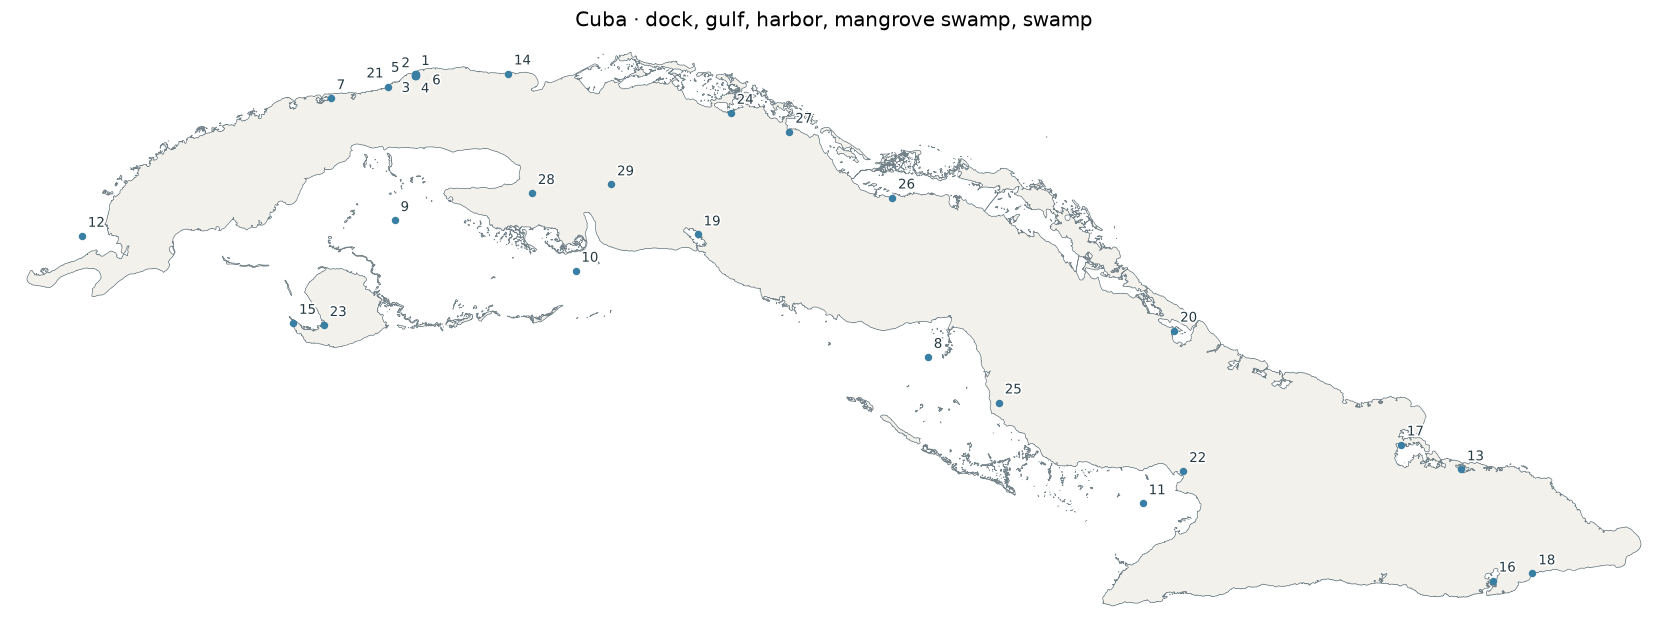

In [6]:
import math
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

land = gpd.read_parquet(ROOT / "data/land-polygons/cuba_land_polygons.parquet")
coastline = gpd.read_parquet(ROOT / "data/coastline/cuba_coastline.parquet")

fig, ax = plt.subplots(figsize=(14, 6))
land.plot(ax=ax, color="#F2F1EB", edgecolor="none")
coastline.plot(ax=ax, color="#74828A", linewidth=0.35)
selected_names.plot(ax=ax, color="#397FA3", markersize=12, zorder=3)

west, south, east, north = land.total_bounds
ax.set_xlim(west - 0.1, east + 0.1)
ax.set_ylim(south - 0.1, north + 0.1)
ax.set_title("Cuba · " + ", ".join(selected_types))
ax.set_axis_off()
fig.tight_layout()
fig.canvas.draw()

# Try nearby positions for each number, keeping every label horizontal.
renderer = fig.canvas.get_renderer()
label_boxes = []
offsets = [(radius * math.cos(angle), radius * math.sin(angle))
           for radius in [5, 10, 16, 24, 34]
           for angle in [math.radians(a) for a in range(45, 405, 45)]]
for row in selected_names.itertuples():
    label = ax.annotate(
        str(row.number), (row.geometry.x, row.geometry.y),
        xytext=(0, 0), textcoords="offset points", fontsize=8,
        color="#263A43", zorder=4,
        path_effects=[pe.withStroke(linewidth=2, foreground="white")],
    )
    for dx, dy in offsets:
        label.set_position((dx, dy))
        label.set_ha("left" if dx >= 0 else "right")
        label.set_va("bottom" if dy >= 0 else "top")
        box = label.get_window_extent(renderer).expanded(1.15, 1.15)
        if not any(box.overlaps(old) for old in label_boxes):
            break
    label_boxes.append(box)

plt.show()


## Use the names with physical features

[Water-body Geometry](../data/water-body-geometry/) and
[River Centerlines](../data/river-centerlines/) link directly to this list:
join their `gazetteer_id` to the name object’s `id` to obtain the preferred name,
alternatives and type. Name objects contain no reverse geometry references.

The physical datasets retain their own geometry and naming status. A null name
ID does not remove an unnamed physical feature.

Continue with [the hydrography map](hydrography_map.ipynb) or the
[ONEI river systems example](onei_river_systems.ipynb).
